# 08 · GPU backends

**What you will see**

- The same world on NVIDIA Isaac Sim (PhysX) and stepped as 1,024 GPU copies (`physics="newton"`), as **measured on an L40S**: the pictures and numbers here are results, nothing is re-run on this Mac.
- Every LeRobot policy family served by LeRobot's own `lerobot-policy-server` over Zenoh, driving a strands sim body on that GPU.

A backend is a choice of engine behind one `Simulation`; robots, policies and the run loop do not change.

In [1]:
from pathlib import Path
from IPython.display import Markdown
import _nb
from strands_robots import Simulation
_nb.show(_nb.drawing("v04_backend"))

## On a CUDA box

```python
from strands_robots import Robot, Simulation

# Isaac Sim (PhysX, RTX rendering): pip install 'strands-robots[isaac]', OMNI_KIT_ACCEPT_EULA=YES
sim = Simulation("isaac")
arm = Robot("so101", sim=sim)
g1 = Robot("unitree_g1", sim=sim, position=[1.0, 0.0, 0.0])
arm.act({"shoulder_pan": 0.5}, steps=200)
image = sim.render()
sim.close()                       # one SimulationApp per process: a second open Simulation("isaac") is refused

# The MuJoCo world stepped by MuJoCo-Warp on the GPU, N copies: pip install 'strands-robots[newton]'
sim = Simulation("mujoco", physics="newton", num_envs=1024)
arm, g1 = Robot("so101", sim=sim), Robot("unitree_g1", sim=sim, position=[1.0, 0.0, 0.0])
sim.step(200)                     # env 0 is mirrored to the CPU for observe/render
```

On this Mac (no CUDA) the same calls refuse by name, before anything is built:

In [2]:
for kw in [dict(backend="isaac"), dict(physics="newton"), dict(num_envs=4)]:
    try:
        Simulation(**kw).close()
        print(kw, "-> opened")
    except (ImportError, ValueError) as exc:
        print(f"{kw}\n  {type(exc).__name__}: {exc}\n")

{'backend': 'isaac'}
  ImportError: Simulation('isaac') needs Isaac Sim: pip install 'strands-robots[isaac]'  (from a checkout: uv pip install -e ".[isaac]") (and OMNI_KIT_ACCEPT_EULA=YES) (No module named 'isaacsim')

{'physics': 'newton'}
  ImportError: physics='newton' needs mujoco_warp + warp: pip install 'strands-robots[newton]'  (from a checkout: uv pip install -e ".[newton]") (No module named 'mujoco_warp')

{'num_envs': 4}
  ValueError: num_envs=4 needs physics='newton'; 'native' steps one world



## Isaac Sim: the SO-101 and the G1 in one PhysX world

MJCF → USD through Isaac's own importers (cached), MuJoCo servo gains authored onto PhysX drives, one articulation per robot. Rendered with Isaac RTX on the L40S.


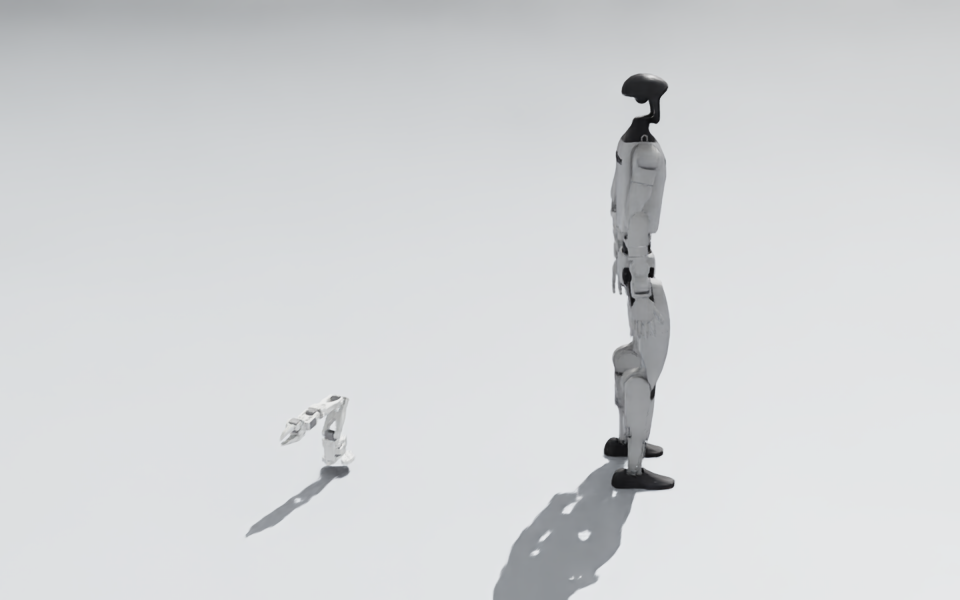

In [3]:
_nb.media("isaac/isaac_so101_g1.png", width=720)

## Newton: 1,024 copies of the same world

`Simulation("mujoco", physics="newton", num_envs=1024)`: MuJoCo builds, reads and renders; MuJoCo-Warp steps every copy in one CUDA graph. The GIF is env 0 of 1,024, the SO-101 waving next to the G1.


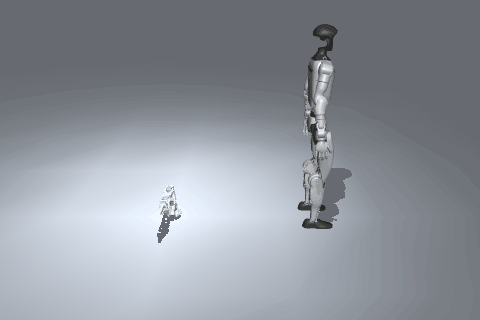

In [4]:
_nb.media("isaac/newton_so101_g1_1024envs.gif", width=480)

## Measured (L40S, isaacsim 6.1.0, mujoco-warp 3.11)

In [5]:
_nb.table([
    {"what": "Isaac: so101 + g1, 1,000 physics steps", "result": "4,336 ms = 231 steps/s (CPU PhysX), render 480×640×3"},
    {"what": "Isaac: app boot / load 2 robots", "result": "10.2 s cold / 1.8 s (USD cache warm)"},
    {"what": "Isaac: Robot.run, 100 steps at 50 Hz", "result": "2.00 s sim time in 5.05 s wall (0.40× real time)"},
    {"what": "Isaac: shared-world tests", "result": "15 passed in 61.26 s; G1 drifts 0.37° while the arm moves"},
    {"what": "Isaac: second open Simulation('isaac')", "result": "refused (one SimulationApp per process); reused after close()"},
    {"what": "Newton: so101 + g1, num_envs=1024", "result": "200 steps in 117 ms = 1,754,372 env-steps/s (1,713 steps/s)"},
    {"what": "Newton: num_envs=1", "result": "2,162 steps/s"},
])

| what | result |
|---|---|
| Isaac: so101 + g1, 1,000 physics steps | 4,336 ms = 231 steps/s (CPU PhysX), render 480×640×3 |
| Isaac: app boot / load 2 robots | 10.2 s cold / 1.8 s (USD cache warm) |
| Isaac: Robot.run, 100 steps at 50 Hz | 2.00 s sim time in 5.05 s wall (0.40× real time) |
| Isaac: shared-world tests | 15 passed in 61.26 s; G1 drifts 0.37° while the arm moves |
| Isaac: second open Simulation('isaac') | refused (one SimulationApp per process); reused after close() |
| Newton: so101 + g1, num_envs=1024 | 200 steps in 117 ms = 1,754,372 env-steps/s (1,713 steps/s) |
| Newton: num_envs=1 | 2,162 steps/s |

**Not there yet on Isaac** (each is a named refusal or an honest value in the tests): `contacts()` returns `[]`; `randomize(friction=, mass=)`, `set_gains` and objects from a file raise `NotImplementedError`; poses agree to ±1e-3 (PhysX float32); GPU PhysX not tried yet; a LeRobot checkpoint on Isaac still needs LeRobot installed in the Isaac environment. `physics="newton"` is MuJoCo-Warp today; the name is still to be settled.

## Every LeRobot policy family, over Zenoh, on a strands body

A real `lerobot-policy-server` per row (config from `policy.lerobot.server_config`), `Policy("zenoh://…/<row>")` → `robot.run(seconds=11)` at 30 Hz. Contract level: admitted, finite, inside the joint limits. **No row claims task success** (base checkpoints are not trained for these scenes).

13 of 25 families admitted; refusals are LeRobot's own or strands' (naming the field), all before any motion. ACT gave identical actions locally and remotely (max abs diff 0.0).

In [6]:
text = (_nb.MEDIA / "gpu-matrix" / "MATRIX.md").read_text()
Markdown(text.split("## Refusals and faults")[0].split("\n", 1)[1])


Contract-level: admitted + finite + inside limits. Only the task gates claim behaviour. Base checkpoints
(e.g. lerobot/smolvla_base) are not so101-trained: a row here is never a task-success claim.

| family | checkpoint | robot | mode | status | admission_ms | first_action_ms | turnaround_p50_ms | turnaround_p95_ms | hz | steps | max_abs_action_rad | max_joint_travel_rad | inside_limits | vram_mib | parity_max_abs_diff |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| ACT (core) | alexis779/so101_ball_cup_act@31ff9e7e | so101 | chunk | admitted | 408.2 | 72.7 | 18.5 | 39.8 | 30.0 | 330 | 0.172 | 0.172 | True | 816 | 0.0 |
| Diffusion (core) | Lebruhbruh/diffusion_so101_pick_cube@f38d5537 | so101 | chunk | refused (lerobot-policy-server) |  |  |  |  |  |  |  |  |  |  |  |
| DM05 (dm05) | alexhegit/so101-simstudio-lab01-pnp-dm05-agent193-10k@a02640ce | so101 | chunk | fault | 227.5 | 704.8 | 690.1 | 690.1 | 29.9 | 23 | 0.158 | 0.158 | True | 20288 |  |
| DM05 (dm05) | alexhegit/so101-simstudio-lab01-pnp-dm05-agent193-10k@a02640ce | so101 | chunk | admitted | 231.0 | 755.6 | 651.5 | 665.5 | 8.0 | 88 | 0.158 | 0.158 | True | 20288 |  |
| EO1 (eo1) | crislmfroes/eo1-openarm-lift-fanta-bottle-clean@74fcfe47 | openarm | chunk | refused (strands, server_config) |  |  |  |  |  |  |  |  |  |  |  |
| EVO1 (evo1) | quangnd58/evo1-so101-multitask@5b6d832c | so101 | chunk | refused (strands, server_config) |  |  |  |  |  |  |  |  |  |  |  |
| EVO1 (evo1) | imstevenpmwork/super_chatton_evo1_stage1_pro@80cd23cd | so101 | chunk | admitted | 226.8 | 338.5 | 293.7 | 310.5 | 30.0 | 330 | 0.993 | 0.993 | True | 4386 |  |
| FastWAM (fastwam) | H2Ozone/fastwam_new_green_2026-07-19_16-26-08@239e1573 | so101 | chunk | refused (LeRobot chunk_inference_spec, config-level) |  |  |  |  |  |  |  |  |  |  |  |
| FineART (fineart_vla) | pepijn223/fineart_vla_super_poulain@ddb98404 | so101 | chunk | admitted | 227.1 | 272.6 | 238.0 | 247.5 | 30.0 | 330 | 0.98 | 0.98 | True | 18856 |  |
| FLUX.3 | 5hadytru/so101_bench_flux-3-action-so101@ac49157c | so101 | chunk | refused (lerobot-policy-server) |  |  |  |  |  |  |  |  |  |  |  |
| G1 SONIC (unitree_g1) | nepyope/sonic_walk@c37a5e42 | unitree_g1 | chunk | refused (strands, server_config) |  |  |  |  |  |  |  |  |  |  |  |
| Gaussian (gaussian_actor) | tiny:gaussian_actor (random, LeRobot defaults)@ | so101 | chunk | refused (lerobot-policy-server) |  |  |  |  |  |  |  |  |  |  |  |
| GR00T (groot) | fatdove/so101-cube-bowl_GR00T17@71dc7eae | so101 | chunk | admitted | 229.3 | 205.6 | 172.4 | 174.2 | 30.0 | 330 | 0.878 | 0.902 | True | 13698 |  |
| LaWAM (lawam) | 5hadytru/so101_bench_LaWAM_full_fine_tune@a7ddd367 | so101 | chunk | admitted | 223.9 | 238.3 | 213.0 | 218.7 | 30.0 | 330 | 1.713 | 1.713 | True | 7566 |  |
| LingBot-VA | lerobot/lingbot_va_base@a9b1da7a | aloha | chunk | refused (lerobot-policy-server) |  |  |  |  |  |  |  |  |  |  |  |
| MolmoAct2 (molmoact2) | XvKuoMing/so101_chess_molmoact2@136a2462 | so101 | chunk | admitted | 418.1 | 273.2 | 244.5 | 247.0 | 30.0 | 330 | 1.57 | 1.57 | True | 14942 |  |
| Multi-task DiT | seriintan/multi_task_dit_frazier@7c38d407 | so101 | chunk | refused (lerobot-policy-server) |  |  |  |  |  |  |  |  |  |  |  |
| π0 (pi) | tonghuiwang123/so100-pi0-new40@54c1c770 | so100 | chunk | admitted | 125.9 | 272.7 | 225.2 | 232.8 | 30.0 | 330 | 2.16 | 1.961 | True | 9474 |  |
| π0.5 (pi) | pdhinaka/pi05_so101_blue_cube_gray_box_cleaned_20k@ffbee39f | so101 | chunk | admitted | 242.6 | 305.4 | 262.0 | 281.1 | 30.0 | 330 | 1.05 | 1.252 | True | 9858 |  |
| π0-FAST (pi) | gpudad/pi0fast-so101-pick-cube@44d2a385 | so101 | chunk | refused (lerobot-policy-server) |  |  |  |  |  |  |  |  |  |  |  |
| SmolVLA (smolvla) | lerobot/smolvla_base@5e8d12a6 | so101 | chunk | admitted | 232.9 | 269.9 | 241.6 | 247.3 | 30.0 | 330 | 0.169 |  | True | 1466 |  |
| SmolVLA (smolvla) | lerobot/smolvla_base@5e8d12a6 | so101 | local | ran |  |  |  |  | 158.4 | 330 | 0.138 | 0.136 | True | 929 |  |
| SmolVLA (smolvla) | lerobot/smolvla_base@5e8d12a6 | so101 | rtc_guided | admitted | 227.6 | 303.0 | 360.0 | 371.4 | 30.0 | 330 | 0.144 |  | True | 2122 |  |
| TD-MPC (core) | tiny:tdmpc (random, LeRobot defaults)@ | so101 | chunk | refused (lerobot-policy-server) |  |  |  |  |  |  |  |  |  |  |  |
| VLA-JEPA (vla_jepa) | charlott-rgb/so101_acrylic_vla_jepa_b8_15000@1e612363 | so101 | chunk | admitted | 218.0 | 138.0 | 105.3 | 107.0 | 30.0 | 330 | 1.521 | 1.521 | True | 6562 |  |
| VQ-BeT (core) | tgibbons/SO-101-VQBET-ball2-claw_30k@5bb580f9 | so101 | chunk | refused (lerobot-policy-server) |  |  |  |  |  |  |  |  |  |  |  |
| WALL-X (wallx) | imstevenpmwork/wall_x_super_chatton@de41b2df | so101 | chunk | refused (lerobot-policy-server) |  |  |  |  |  |  |  |  |  |  |  |
| XVLA (xvla) | imstevenpmwork/xvla_super_chatton_2@36fbf138 | so101 | chunk | admitted* | 225.9 | 971.8 | 107.6 | 109.2 | 30.0 | 330 | 1.23 | 1.23 | True | 2340 |  |

\* ran on a local copy whose config.json was patched (the published config is stale):

- **xvla**: `{"input_features": {"observation.state": {"type": "STATE", "shape": [6]}, "observation.images.image": {"type": "VISUAL", "shape": [3, 256, 256]}, "observation.images.image2": {"type": "VISUAL", "shape": [3, 256, 256]}}}`

## Robustness (cuda, real lerobot-policy-server processes; scripts/matrix_robust.py)

- **robust_busy** pass=True: `{"second_client": "AdmissionDeniedError: Remote admission denied for deployment 'busy': another client owns the deployment; stop that client before retrying.", "second_client_steps": 0, "first_client_steps": 92, "sessions_admitted": 1}`
- **robust_contract** pass=True: `{"wrong_camera": {"refused": true, "message": "ValueError: Policy('zenoh://127.0.0.1:7822/contract') needs camera(s) ['wrist'] but the observation has ['front']: add them with sim.camera(name, size=(w, h), attach=robot) or cameras={name: index} on hardware"}, "wrong_state_width": {"refused": true, "message": "ValueError: deployment state component 'shoulder_pan.pos' is not a joint of aloha (action keys: ['left/waist', 'left/shoulder', 'left/elbow', 'left/forearm_roll', 'left/wrist_angle', 'left/wrist_rotate', 'left/left_finger', 'right/waist', 'right/shoulder', 'right/elbow', 'right/forearm_roll', 'right/wrist_angle', 'right/wrist_rotate', 'right/left_finger']); a LeRobot name is '<action key>.pos'"}, "sessions_admitted": 0, "wrong_semantics": {"refused": true, "message": "ValueError: unknown LeRobot semantics 'furlongs-v1': add it to strands_robots/units/semantics.json (known: koch-range-gripper-percent-v1, radians-v1, so100-degrees-gripper-percent-v1, so100-range-gripper-percent-v1, so101-degrees-gripper-percent-v1, so101-range-gripper-percent-v1) or pass units= explicitly"}, "sessions_admitted_sem": 0}`
- **robust_kill** pass=True: `{"checkpoint": "alexis779/so101_ball_cup_act@31ff9e7e", "grace_s": 1.0, "stopped_by": "fault", "fault": "Policy('zenoh://127.0.0.1:7821/kill'): Server presence was lost during control acknowledgement", "steps": 155, "kill_to_fault_s": 0.573, "kill_to_end_s": 0.576, "acts_after_fault": 0, "steps_after_kill": 17, "held_target_max_dev_rad": 0.0011474129688067158}`
- **robust_two** pass=True: `{"ids": ["so101", "so101_2"], "wall_s": 10.93, "left": {"steps": 300, "stopped_by": "steps"}, "right": {"steps": 300, "stopped_by": "steps"}, "sessions": [["2dd4fc2198cd4398b78137a73841c543"], ["d0ca3de6885a4505aa1e1e7b16371b3c"]], "distinct_sessions": true}`



## Where this sits in v1

Part 6 (`simulation/backends/isaac/`, `simulation/backends/newton/`) and the GPU check of part 4. Both backends import no GPU stack until they are chosen, so the package stays light on a laptop.